In [1]:
# Imports
import json
import time
from pathlib import Path

import torch
from PIL import Image, ImageDraw
from transformers import AutoModelForCausalLM, AutoProcessor
from rapidocr_onnxruntime import RapidOCR

torch.set_num_threads(torch.get_num_threads())  # use all CPU cores
print("torch", torch.__version__, "| threads:", torch.get_num_threads())

torch 2.14.1+cpu | threads: 3


data/raw/1_updated_resized.jpg (600, 400)


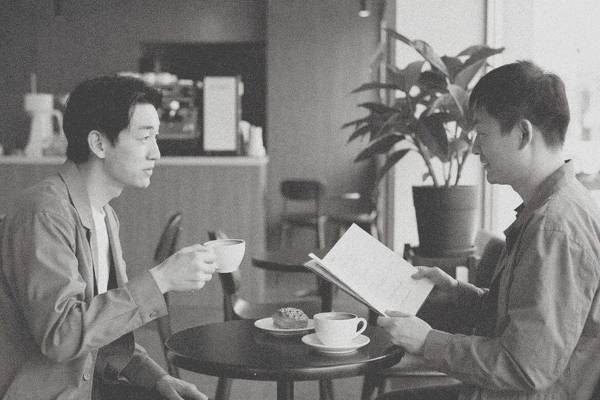

In [2]:
# Paths and source image
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
IMAGE_PATH = RAW_DIR / "1_updated_resized.jpg"

assert IMAGE_PATH.exists(), f"missing {IMAGE_PATH}"
image = Image.open(IMAGE_PATH).convert("RGB")
print(IMAGE_PATH, image.size)
image

In [3]:
# Load Florence-2 (CV model)
MODEL_ID = "microsoft/Florence-2-base"
DEVICE = "cpu"

t0 = time.time()
florence = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    torch_dtype=torch.float32,
    attn_implementation="eager",
).to(DEVICE).eval()
processor = AutoProcessor.from_pretrained(MODEL_ID, trust_remote_code=True)
print(f"Florence-2 loaded in {time.time() - t0:.1f}s")

Florence-2 loaded in 7.2s


In [4]:
# Load RapidOCR engine
ocr_engine = RapidOCR()
print("RapidOCR OK")

RapidOCR OK


In [5]:
# Helper: run one Florence-2 task prompt
def run_florence(task, image, text_input=""):
    """Run one Florence-2 task prompt and return the parsed result."""
    prompt = task + text_input
    inputs = processor(text=prompt, images=image, return_tensors="pt").to(DEVICE)
    with torch.inference_mode():
        ids = florence.generate(
            input_ids=inputs["input_ids"],
            pixel_values=inputs["pixel_values"],
            max_new_tokens=256,
            num_beams=3,
            do_sample=False,
            use_cache=False,  # avoids a cache bug with the pinned remote code
        )
    text = processor.batch_decode(ids, skip_special_tokens=False)[0]
    return processor.post_process_generation(
        text, task=task, image_size=(image.width, image.height)
    )

In [6]:
# Detailed caption
t0 = time.time()
caption = run_florence("<MORE_DETAILED_CAPTION>", image)["<MORE_DETAILED_CAPTION>"]
print(f"{time.time() - t0:.1f}s")
print(caption)

73.3s
The image is a black and white photograph of two men sitting at a round table in a cafe or restaurant. The man on the left is holding a cup of coffee and appears to be engaged in a conversation with the other man. They are both wearing casual clothes and appear to be in their late twenties or early thirties.

The table is covered with a white tablecloth and there is a small plate of food on it. On the right side of the table, there are two cups of tea and a book. In the background, there is another table with a potted plant and a coffee machine. The overall mood of the image is relaxed and casual.


In [7]:
# Object detection
t0 = time.time()
od = run_florence("<OD>", image)["<OD>"]
print(f"{time.time() - t0:.1f}s")
for label, box in zip(od["labels"], od["bboxes"]):
    print(label, [round(v) for v in box])

21.5s
coffee cup [312, 311, 369, 346]
coffee cup [203, 238, 248, 273]
houseplant [338, 27, 512, 259]
human face [105, 103, 163, 188]
human face [469, 107, 522, 184]
man [371, 59, 599, 399]
man [0, 75, 221, 399]
saucer [302, 333, 372, 354]
table [153, 312, 422, 399]


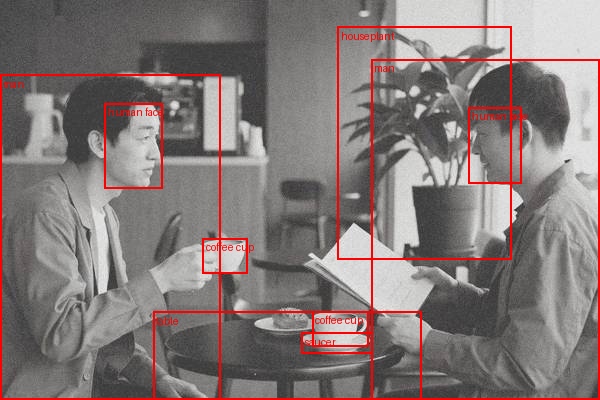

In [8]:
# Helper + overlay of detected boxes
def draw_boxes(image, labels, bboxes):
    img = image.copy()
    draw = ImageDraw.Draw(img)
    for label, (x1, y1, x2, y2) in zip(labels, bboxes):
        draw.rectangle([x1, y1, x2, y2], outline="red", width=2)
        draw.text((x1 + 3, y1 + 3), label, fill="red")
    return img

draw_boxes(image, od["labels"], od["bboxes"])

In [9]:
# Save CV result to data/processed
cv_result = {
    "image": str(IMAGE_PATH),
    "size": list(image.size),
    "caption": caption,
    "objects": [
        {"label": l, "bbox": [round(v, 1) for v in b]}
        for l, b in zip(od["labels"], od["bboxes"])
    ],
}
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out_path = PROCESSED_DIR / f"{IMAGE_PATH.stem}_cv.json"
out_path.write_text(json.dumps(cv_result, indent=2, ensure_ascii=False))
print("saved", out_path)

saved data/processed/1_updated_resized_cv.json
